## 06 .Final Insights Summary

In [2]:
## Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
# 1. Load All Required Data

PROCESSED_PATH = "../data/processed/"

orders = pd.read_csv(PROCESSED_PATH + "orders_clean.csv")
master = pd.read_csv(PROCESSED_PATH + "master_order_fact.csv")
rfm = pd.read_csv(PROCESSED_PATH + "rfm_segments.csv")
returns = pd.read_csv(PROCESSED_PATH + "returns_clean.csv")
shipments = pd.read_csv(PROCESSED_PATH + "shipments_clean.csv")
payments = pd.read_csv(PROCESSED_PATH + "payments_clean.csv")
reviews = pd.read_csv(PROCESSED_PATH + "reviews_clean.csv")
customers = pd.read_csv(PROCESSED_PATH + "customers_clean.csv")

orders['order_date'] = pd.to_datetime(orders['order_date'])

print("All data loaded successfully!")

All data loaded successfully!


In [4]:
# 2. High-Level Business Metrics

print("\n" + "="*60)
print("HIGH-LEVEL BUSINESS METRICS")
print("="*60)

total_orders = orders['order_id'].nunique()
total_revenue = orders['final_amount'].sum()
total_customers = orders['customer_id'].nunique()
aov = orders['final_amount'].mean()
total_returns = returns.shape[0]
return_rate = (total_returns / total_orders) * 100

print(f"Total Orders           : {total_orders:,}")
print(f"Total Revenue          : ₹{total_revenue:,.2f}")
print(f"Total Customers        : {total_customers:,}")
print(f"Average Order Value    : ₹{aov:,.2f}")
print(f"Total Returns          : {total_returns:,}")
print(f"Overall Return Rate    : {return_rate:.2f}%")


HIGH-LEVEL BUSINESS METRICS
Total Orders           : 100,000
Total Revenue          : ₹2,572,592,368.57
Total Customers        : 22,820
Average Order Value    : ₹25,725.92
Total Returns          : 12,075
Overall Return Rate    : 12.07%



CUSTOMER SEGMENTATION SUMMARY (RFM)
           Segment  Customer_Count
0          At Risk            4945
1  Loyal Customers            4485
2        Champions            4262
3             Lost            4163
4        Promising            2967
5   Need Attention            1998


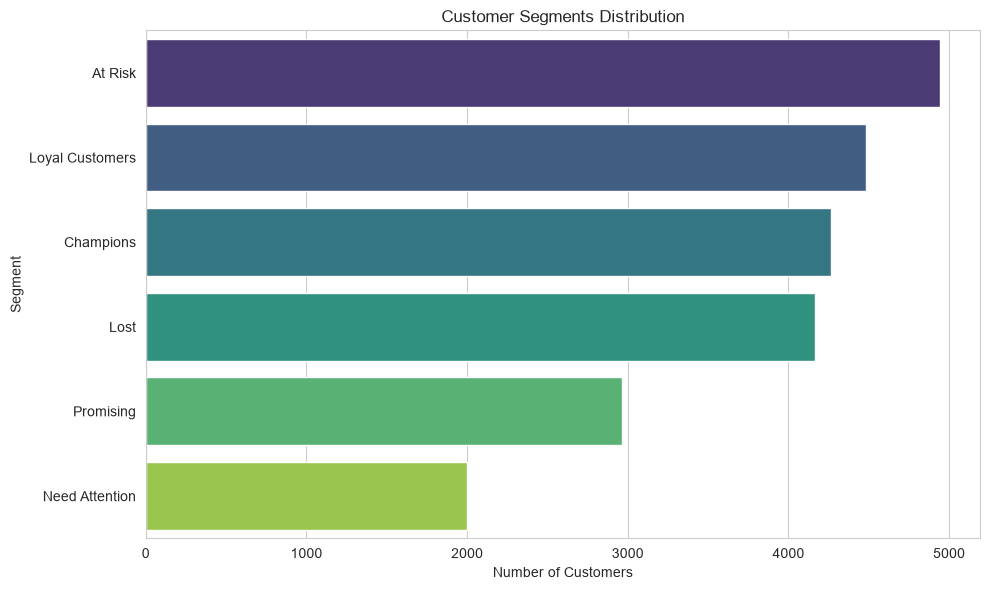

In [7]:
# 3. Customer Segmentation Summary (RFM)
print("\n" + "="*60)
print("CUSTOMER SEGMENTATION SUMMARY (RFM)")
print("="*60)

segment_summary = rfm['Segment'].value_counts().reset_index()
segment_summary.columns = ['Segment', 'Customer_Count']
print(segment_summary)

plt.figure(figsize=(10, 6))
sns.barplot(data=segment_summary, x='Customer_Count', y='Segment', palette='viridis', hue='Segment')
plt.title("Customer Segments Distribution")
plt.xlabel("Number of Customers")
plt.tight_layout()
plt.show()


PAYMENTS ANALYSIS

Payment Method Distribution:
payment_method
UPI                 31971
Cash on Delivery    17274
Credit Card         15063
Debit Card          12682
Net Banking          8322
Wallet               6989
EMI                  3889
Pay Later            1825
Gift Card            1046
Cardless EMI          939
Name: count, dtype: int64


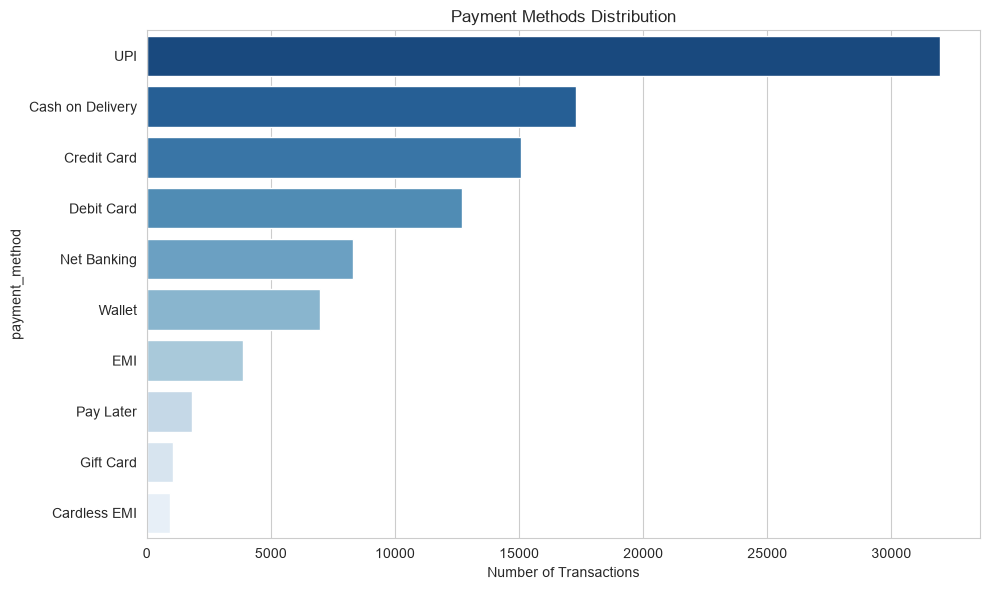


Payment Status:
payment_status
Success        82137
Refunded       10690
Failed          5068
Not Charged     1876
Pending          229
Name: count, dtype: int64


In [ ]:
# 4. Payments Analysis

print("\n" + "="*60)
print("PAYMENTS ANALYSIS")
print("="*60)

### Payment Method Distribution

payment_method_counts = payments['payment_method'].value_counts()
print("\nPayment Method Distribution:")
print(payment_method_counts)

plt.figure(figsize=(10, 6))
sns.barplot(x=payment_method_counts.values, y=payment_method_counts.index, palette='Blues_r',hue=payment_method_counts.index)
plt.title("Payment Methods Distribution")
plt.xlabel("Number of Transactions")
plt.tight_layout()
plt.show()

# Payment Status

payment_status = payments['payment_status'].value_counts()
print("\nPayment Status:")
print(payment_status)




CUSTOMER REVIEWS ANALYSIS

Rating Distribution:
rating
1      700
2     6311
3    24208
4    31265
5    15046
Name: count, dtype: int64


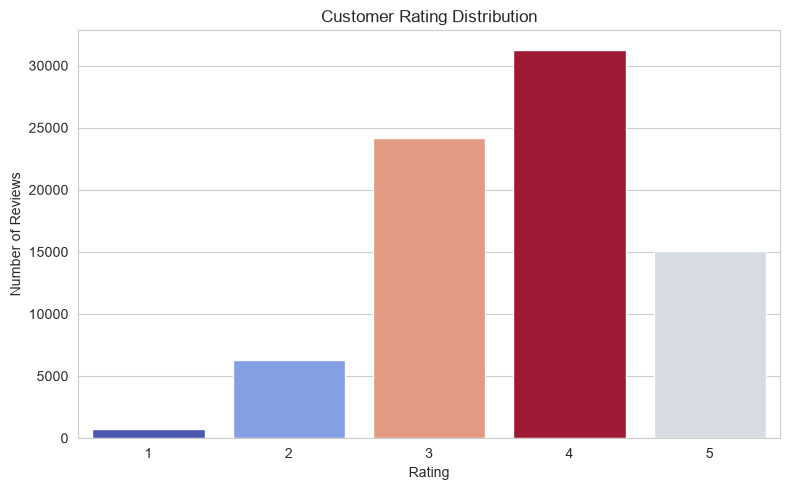


Review Sentiment Distribution:
review_sentiment
Positive    46311
Neutral     24208
Negative     7011
Name: count, dtype: int64


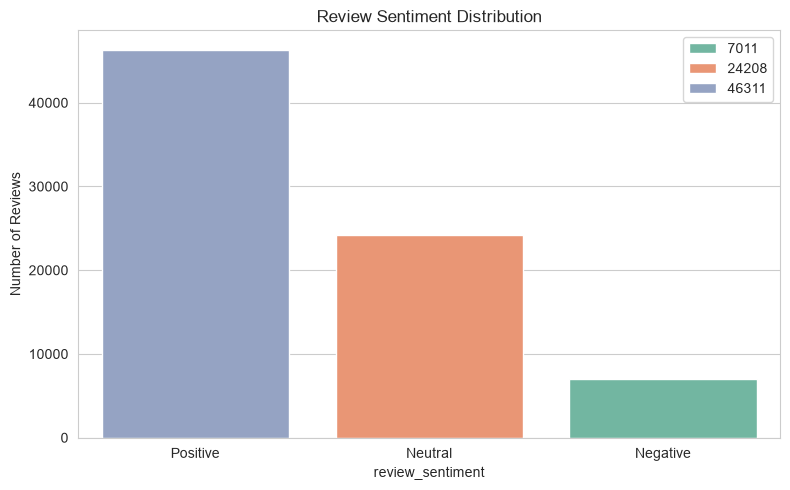


Average Customer Rating: 3.69 / 5


In [21]:
# 5. Customer Reviews Analysis

print("\n" + "="*60)
print("CUSTOMER REVIEWS ANALYSIS")
print("="*60)

### Rating Distribution
rating_counts = reviews['rating'].value_counts().sort_index()
print("\nRating Distribution:")
print(rating_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='coolwarm',hue=rating_counts.values, legend=False)
plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Sentiment Distribution
sentiment_counts = reviews['review_sentiment'].value_counts()
print("\nReview Sentiment Distribution:")
print(sentiment_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette='Set2',hue=sentiment_counts.values)
plt.title("Review Sentiment Distribution")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Average Rating
avg_rating = reviews['rating'].mean()
print(f"\nAverage Customer Rating: {avg_rating:.2f} / 5")

In [22]:
# 6. Returns & Delivery Quick Summary

print("\n" + "="*60)
print("RETURNS & DELIVERY QUICK SUMMARY")
print("="*60)

print("Top 5 Return Reasons:")
print(returns['return_reason'].value_counts().head(5))

delayed_pct = (shipments['delayed_flag'].sum() / len(shipments)) * 100
print(f"\nPercentage of Delayed Deliveries: {delayed_pct:.2f}%")


RETURNS & DELIVERY QUICK SUMMARY
Top 5 Return Reasons:
return_reason
Size issue                 2201
Changed mind               1984
Product damaged            1933
Quality issue              1692
Product not as expected    1442
Name: count, dtype: int64

Percentage of Delayed Deliveries: 41.76%


#### Final Business Insights & Recommendations

1. Sales Performance:
   - Focus on top-performing categories and states to maximize revenue.
   - Monitor monthly trends for seasonality and plan inventory accordingly.

2. Customer Segmentation (RFM):
   - Champions & Loyal customers should be targeted with loyalty programs.
   - At Risk and Lost customers need win-back campaigns.

3. Payments:
   - UPI and popular methods dominate — ensure smooth experience on these.
   - Monitor failed payments to reduce revenue leakage.

4. Customer Reviews:
   - Overall rating is a key health metric of customer satisfaction.
   - Negative sentiment reviews should be analyzed for product improvement.

5. Returns:
   - High return reasons (e.g. Size issue) should be addressed with better product information.
   - Categories with high returns need quality or description improvements.

6. Delivery:
   - Reduce delivery delays as they can increase returns and lower customer satisfaction.